# Eksploracja zbioru LGG MRI

Celem notebooka jest poznanie danych, sprawdzenie par obraz–maska i przygotowanie tabel metadanych.
Główna część prowadzi od lokalizacji plików do zapisu `pairs.csv` i `patients.csv`.
Drobne ćwiczenia z wcześniejszej pracy pozostają na końcu, oznaczone jako **DO ROZWAŻENIA USUNIĘCIA**.

Uruchamiaj komórki od góry, z kernelem **Python (inzynierka)**. Przyjęto uruchamianie z katalogu projektu lub `notebooks/`.
Dane należy wcześniej rozpakować do `data/raw/`; notebook ich nie pobiera.

Opis źródła: [LGG MRI Segmentation — Kaggle](https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation)
oraz lokalny `data/raw/README.md`.
Każdy katalog odpowiada przypadkowi pacjenta. Maski oznaczają nieprawidłowości widoczne we FLAIR;
pusta maska mówi o braku oznaczenia na przekroju, a nie o braku choroby u pacjenta.

## 1. Biblioteki i ścieżki

`pathlib` służy do obsługi ścieżek, `tifffile` do odczytu TIFF, NumPy do kontroli tablic,
Pandas do tabel, a Matplotlib do wizualizacji.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tifffile
import pandas as pd

Ścieżki budujemy względem katalogu projektu, bez wpisywania lokalnej ścieżki użytkownika.
`Path.cwd()` oznacza katalog roboczy kernela, więc poniższe rozpoznanie zakłada katalog projektu lub jego `notebooks/`.

In [2]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw"
metadata_dir = project_root / "data" / "metadata"
if not data_dir.is_dir():
    raise FileNotFoundError(f"Nie znaleziono katalogu danych: {data_dir}")


## 2. Katalogi pacjentów

Uwzględniamy bezpośrednie podkatalogi `data/raw/`, pomijając pliki takie jak `data.csv` i `README.md`.
Sortowanie nazw daje stałą kolejność przeglądania. W dotychczasowym audycie znaleźliśmy 110 katalogów.

In [3]:
# Bezpośrednie podkatalogi w folderze raw.
patients_dir = sorted(d for d in data_dir.iterdir() if d.is_dir())
print("Liczba katalogów pacjentów:", len(patients_dir))


Liczba katalogów pacjentów: 110


## 3. Audyt plików i zebranie rekordów

Obraz `..._<numer>.tif` łączymy z maską `..._<numer>_mask.tif` według nazw, a nie pozycji na liście.
Sprawdzamy brakujące maski, maski bez obrazu, wymiary, typy danych i wartości występujące w maskach.

`checked_pairs` liczy wszystkie odczytane pary, także te z błędnymi wymiarami.
Oczekiwane kształty to `(256, 256, 3)` dla obrazu i `(256, 256)` dla maski.
Rekord zachowuje wynik kontroli w `correct_shape`; nie odrzucamy tu par automatycznie.
`foreground_pixels` liczy niezerowe piksele, a `has_annotation` informuje, czy takie piksele istnieją.

Listy i liczniki zerujemy przy każdym uruchomieniu tej komórki.
Każda maska sparowana jest obecnie odczytywana w obu pętlach — pozostawiamy ten poznany układ kodu.

In [4]:
missing_masks = []
orphan_masks = []
shape_errors = []
checked_pairs = 0

image_dtypes = set()
mask_dtypes = set()
mask_values = set()

records = []

for p_dir in patients_dir:
    sub_p_dir = sorted([d for d in p_dir.iterdir() if d.is_file()])
    patient_dir_imgs = [f for f in sub_p_dir if f.suffix == ".tif" and not (f.stem).endswith("_mask")]
    patient_dir_masks = [f for f in sub_p_dir if f.suffix == ".tif" and (f.stem).endswith("_mask")]
    
    for image_path in patient_dir_imgs:
        mask_name = image_path.stem + "_mask" + image_path.suffix
        mask_path = image_path.with_name(mask_name)
        
        image = tifffile.imread(image_path)
        image_dtypes.add(str(image.dtype))
        
        if not mask_path.is_file():
            missing_masks.append(mask_path)
        else:
            mask = tifffile.imread(mask_path)
            checked_pairs += 1
            
            pair = {}
            pair["patient_id"] = p_dir.name
            pair["image_path"] = str(image_path)
            pair["mask_path"] = str(mask_path)
            pair["correct_shape"] = (image.shape == (256, 256, 3) and mask.shape == (256, 256))
            pair["slice_id"] = int(image_path.stem.rsplit("_", 1)[1])
            pair["foreground_pixels"] = np.count_nonzero(mask)
            pair["has_annotation"] = bool(pair["foreground_pixels"] > 0)
            records.append(pair)
    
            if image.shape != (256, 256, 3) or mask.shape != (256, 256):
                shape_errors.append((image_path, image.shape, mask.shape))
      

    for mask_path in patient_dir_masks:
        image_name = mask_path.stem.removesuffix("_mask") + mask_path.suffix
        image_path = mask_path.with_name(image_name)
        
        mask = tifffile.imread(mask_path)
        mask_dtypes.add(str(mask.dtype))
        mask_values.update(np.unique(mask))
        
        if not image_path.is_file():
            orphan_masks.append(mask_path)     
        
print("Brakujące maski:", len(missing_masks))
print("Błędy wymiarów:", len(shape_errors))
print("Maski bez obrazu:", len(orphan_masks))
print("Typy obrazów:", image_dtypes)
print("Typy masek:", mask_dtypes)
print("Wartości masek:", sorted(int(value) for value in mask_values))
print("Odczytane pary:", checked_pairs)


Brakujące maski: 0
Błędy wymiarów: 0
Maski bez obrazu: 0
Typy obrazów: {'uint8'}
Typy masek: {'uint8'}
Wartości masek: [0, 255]
Odczytane pary: 3929


## 4. Tabela par i tabela pacjentów

Każdy wiersz `df` opisuje jedną parę. `slice_id` jest liczbą wyciągniętą z nazwy pliku,
więc sortowanie daje kolejność `1, 2, 3, ...`, zamiast tekstowej `1, 10, 11, ...`.
Sam numer pliku nie określa odległości między przekrojami ani położenia w milimetrach.

In [5]:
df = pd.DataFrame(records).sort_values(["patient_id", "slice_id"]).reset_index(drop=True)
print(df.shape)
df.head()

(3929, 7)


,patient_id,image_path,mask_path,correct_shape,slice_id,foreground_pixels,has_annotation
0,TCGA_CS_4941_19960909,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,True,1,0,False
1,TCGA_CS_4941_19960909,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,True,2,0,False
2,TCGA_CS_4941_19960909,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,True,3,0,False
3,TCGA_CS_4941_19960909,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,True,4,0,False
4,TCGA_CS_4941_19960909,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,C:\Users\ci3nk\Desktop\inzynierka\data\raw\TCG...,True,5,0,False


Kontrola tabeli obejmuje liczbę pacjentów, wyniki kontroli wymiarów i powtórzone ścieżki obrazów.
Dotychczasowy wynik: 110 pacjentów, 3929 poprawnych wymiarowo par i brak duplikatów ścieżek.

In [6]:
print("liczba pacjentów: ", df["patient_id"].nunique())
print("liczebność wartości w correct_shape", df["correct_shape"].value_counts())
print("\nliczba powtórzonych ścieżek obrazów: ", df["image_path"].duplicated().sum())

liczba pacjentów:  110
liczebność wartości w correct_shape correct_shape
True    3929
Name: count, dtype: int64

liczba powtórzonych ścieżek obrazów:  0


`patient_df` zawiera jeden wiersz na pacjenta. Zliczamy jego przekroje oraz przekroje z oznaczeniem.
Sumowanie `has_annotation` działa, ponieważ `True` liczy się jako 1, a `False` jako 0.

In [7]:
patient_df = df.groupby("patient_id").agg(
    n_slices=("slice_id", "count"),
    n_annotated_slices=("has_annotation", "sum")
).reset_index()
patient_df

,patient_id,n_slices,n_annotated_slices
0,TCGA_CS_4941_19960909,23,8
1,TCGA_CS_4942_19970222,20,6
2,TCGA_CS_4943_20000902,20,8
3,TCGA_CS_4944_20010208,20,9
4,TCGA_CS_5393_19990606,20,8
...,...,...,...
105,TCGA_HT_8563_19981209,23,9
106,TCGA_HT_A5RC_19990831,32,15
107,TCGA_HT_A616_19991226,28,11
108,TCGA_HT_A61A_20000127,88,37


Sprawdzamy zgodność obu tabel: sumę przekrojów, sumę przekrojów z oznaczeniem
oraz warunek `0 ≤ n_annotated_slices ≤ n_slices` dla każdego pacjenta.
Trzy wyniki `True` oznaczają spełnienie tych warunków.

In [8]:
print(patient_df["n_slices"].sum() == len(df))
print(patient_df["n_annotated_slices"].sum() == df["has_annotation"].sum())
print(( (patient_df["n_slices"] >= patient_df["n_annotated_slices"]) 
        & (patient_df["n_annotated_slices"] >= 0) ).all())

True
True
True


## 5. Przykładowa para i trzy kanały MRI

Wybieramy pierwszy przekrój z oznaczeniem u pierwszego pacjenta z posortowanej tabeli.
Odczytujemy parę jawnie, aby wykres nie zależał od wartości zmiennych pozostawionych przez pętle audytu.
Zmienne z prefiksem `example_` dotyczą wyłącznie tego przykładu.

In [9]:
example_patient_id = df["patient_id"].iloc[0]
example_pair = df[
    (df["patient_id"] == example_patient_id) & df["has_annotation"]
].iloc[0]

example_image_path = Path(example_pair["image_path"])
example_mask_path = Path(example_pair["mask_path"])
example_image = tifffile.imread(example_image_path)
example_mask = tifffile.imread(example_mask_path)

print("Przykładowy obraz:", example_image_path.name)
print("Przykładowa maska:", example_mask_path.name)


Przykładowy obraz: TCGA_CS_4941_19960909_11.tif
Przykładowa maska: TCGA_CS_4941_19960909_11_mask.tif


Według lokalnego `README.md` kolejność kanałów to: przed kontrastem, FLAIR, po kontraście.
Brakujące sekwencje zastąpiono FLAIR, dlatego trzy kanały nie zawsze oznaczają trzy różne sekwencje.

`image[:, :, c]` wybiera wszystkie wiersze i kolumny kanału `c`.
Wspólne `vmin=0, vmax=255` zapewniają tę samą skalę jasności, a czerwony kontur pokazuje granicę oznaczenia.
Opcjonalne wypełnienie przez `contourf` pozostaje zakomentowane.

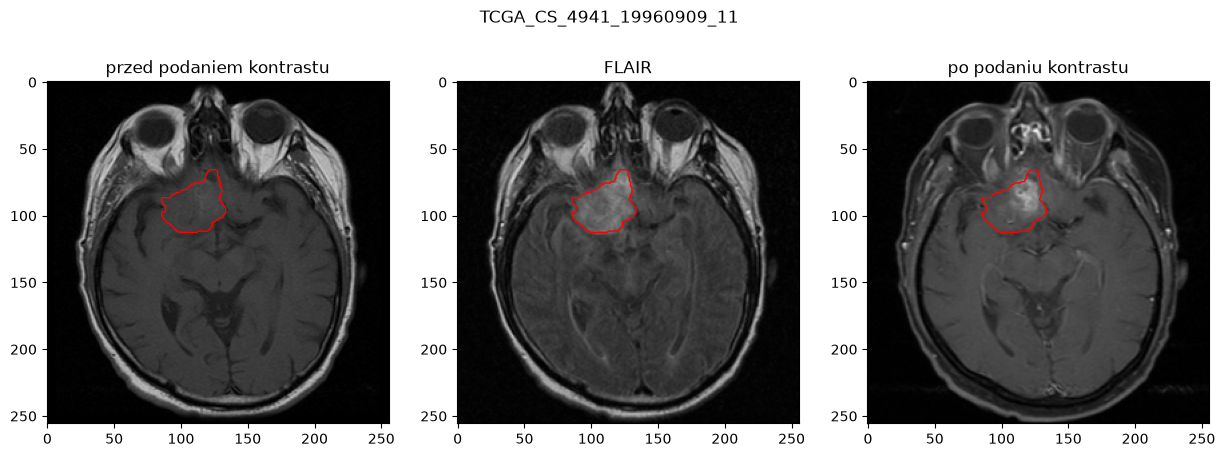

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ["przed podaniem kontrastu", "FLAIR", "po podaniu kontrastu"]
fig.suptitle(example_image_path.stem)
for c in range(3):
    axes[c].imshow(example_image[:, :, c], cmap="gray", vmin=0, vmax=255)
    axes[c].contour(example_mask > 0, levels=[0.5], colors="red", linewidths=1)
    # axes[c].contourf(example_mask > 0, levels=[0.5, 1.5], colors="red", alpha=0.1)
    axes[c].set_title(titles[c])
    
plt.show()


## 6. Ścieżki względne i zapis metadanych

Do zapisu tworzymy kopię `df`. Ścieżki w CSV zaczynają się od `data/raw/`, dzięki czemu można
przenieść projekt bez zmiany każdej ścieżki. Po odczycie pełną ścieżkę zbudujemy jako
`project_root / zapisana_sciezka`.
`patient_df` zawiera podsumowania, więc nie wymaga zmiany ścieżek.

In [11]:
def rel_path(p):
    return Path(p).relative_to(project_root).as_posix()

metadata_df = df.copy()
metadata_df["image_path"] = metadata_df["image_path"].map(rel_path)
metadata_df["mask_path"] = metadata_df["mask_path"].map(rel_path)

metadata_df.head()


,patient_id,image_path,mask_path,correct_shape,slice_id,foreground_pixels,has_annotation
0,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,1,0,False
1,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,2,0,False
2,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,3,0,False
3,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,4,0,False
4,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,5,0,False


Poniższa komórka zapisuje (i przy ponownym wykonaniu nadpisuje) `pairs.csv` i `patients.csv`
w `data/metadata/`. `index=False` pomija techniczny indeks DataFrame.

In [12]:
metadata_df.to_csv(metadata_dir / "pairs.csv", index=False)
patient_df.to_csv(metadata_dir / "patients.csv", index=False)


Odczytujemy zapisane pliki, aby obejrzeć ich kształt i początkowe wiersze.
Nazwy `pairs_loaded` i `patients_loaded` oznaczają odczyt z CSV; nie są to zbiory testowe modelu.
Oczekiwane rozmiary po dotychczasowym audycie: `(3929, 7)` oraz `(110, 3)`.

In [13]:
pairs_loaded = pd.read_csv(metadata_dir / "pairs.csv")
print("Tabela par po odczycie:", pairs_loaded.shape)
pairs_loaded.head()


Tabela par po odczycie: (3929, 7)


,patient_id,image_path,mask_path,correct_shape,slice_id,foreground_pixels,has_annotation
0,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,1,0,False
1,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,2,0,False
2,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,3,0,False
3,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,4,0,False
4,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,True,5,0,False


In [14]:
patients_loaded = pd.read_csv(metadata_dir / "patients.csv")
print("Tabela pacjentów po odczycie:", patients_loaded.shape)
patients_loaded.head()


Tabela pacjentów po odczycie: (110, 3)


,patient_id,n_slices,n_annotated_slices
0,TCGA_CS_4941_19960909,23,8
1,TCGA_CS_4942_19970222,20,6
2,TCGA_CS_4943_20000902,20,8
3,TCGA_CS_4944_20010208,20,9
4,TCGA_CS_5393_19990606,20,8
